# Y.Afisha: where should the marketing money go?

Y.Afisha sells tickets for events. The marketing team spends money on several ad sources, and the business is not sure that every source pays for itself. The goal of this project is to recommend where to invest, based on three files:

- the server logs with every visit to the site
- every order made in the period
- the daily marketing costs of each ad source

The project has five steps and a conclusion:

1. Loading and preparing the data
2. Product: how people use the site
3. Sales: when they buy and how much they bring
4. Marketing: how much each source costs and if it pays back
5. Hypothesis test: do desktop customers spend more than touch customers?

## Step 1. Loading and preparing the data

The visits file is big, so a sample of 500 rows is read first to choose the right data types. Then the three files are loaded, the column names are fixed and the data is checked: missing values, duplicates, period, session length, ad sources and order values. What needs cleaning is cleaned at the end of the step.

The money values are in US dollars (the files end in `_us`). `Device` is desktop or touch, where touch means phones and tablets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

In [2]:
# Path to the files. To run the notebook in another place, change only this line
path = '../data/01_raw/'

#### Optimizing data

In [3]:
visits_sample = pd.read_csv(path + 'visits_log_us.csv', nrows=500)
visits_sample.info(memory_usage='deep')
visits_sample.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Device     500 non-null    object
 1   End Ts     500 non-null    object
 2   Source Id  500 non-null    int64 
 3   Start Ts   500 non-null    object
 4   Uid        500 non-null    uint64
dtypes: int64(1), object(3), uint64(1)
memory usage: 113.1 KB


,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


In [4]:
visits_sample['Device'].value_counts()

Device
desktop    363
touch      137
Name: count, dtype: int64

In [5]:
# The dates were read as text, and Device has only two values (desktop and touch).
# So the files are loaded with the right types from the start
visits = pd.read_csv(
    path + 'visits_log_us.csv',
    dtype={'Device': 'category'},
    parse_dates=['Start Ts', 'End Ts']
)
orders = pd.read_csv(path + 'orders_log_us.csv', parse_dates=['Buy Ts'])
costs = pd.read_csv(path + 'costs_us.csv', parse_dates=['dt'])

In [6]:
visits.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Device     359400 non-null  category      
 1   End Ts     359400 non-null  datetime64[ns]
 2   Source Id  359400 non-null  int64         
 3   Start Ts   359400 non-null  datetime64[ns]
 4   Uid        359400 non-null  uint64        
dtypes: category(1), datetime64[ns](2), int64(1), uint64(1)
memory usage: 11.3 MB


In [7]:
# Same file read without the types, only to compare the size
visits_raw_mb = pd.read_csv(path + 'visits_log_us.csv').memory_usage(deep=True).sum() / 1024**2
visits_mb = visits.memory_usage(deep=True).sum() / 1024**2

print(f'Without the types: {visits_raw_mb:.1f} MB')
print(f'With the types: {visits_mb:.1f} MB')
print(f'Reduction: {1 - visits_mb / visits_raw_mb:.0%}')

Without the types: 79.3 MB
With the types: 11.3 MB
Reduction: 86%


In [8]:
orders.info(memory_usage='deep')
costs.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Buy Ts   50415 non-null  datetime64[ns]
 1   Revenue  50415 non-null  float64       
 2   Uid      50415 non-null  uint64        
dtypes: datetime64[ns](1), float64(1), uint64(1)
memory usage: 1.2 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   source_id  2542 non-null   int64         
 1   dt         2542 non-null   datetime64[ns]
 2   costs      2542 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 59.7 KB


#### Column names

In [9]:
# Lower case with underscores, the same style as the costs table
visits.columns = visits.columns.str.lower().str.replace(' ', '_')
orders.columns = orders.columns.str.lower().str.replace(' ', '_')

print(visits.columns.tolist())
print(orders.columns.tolist())
print(costs.columns.tolist())

['device', 'end_ts', 'source_id', 'start_ts', 'uid']
['buy_ts', 'revenue', 'uid']
['source_id', 'dt', 'costs']


In [10]:
# First look at the three tables
display(visits.head())
display(orders.head())
display(costs.head())

,device,end_ts,source_id,start_ts,uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168


,buy_ts,revenue,uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844
3,2017-06-01 00:29:00,0.55,16109239769442553005
4,2017-06-01 07:58:00,0.37,14200605875248379450


,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53
3,1,2017-06-04,55.00
4,1,2017-06-05,57.08


#### Missing values and duplicates

In [11]:
for name, df in {'visits': visits, 'orders': orders, 'costs': costs}.items():
    print(f'{name}: {df.isna().sum().sum()} missing values | {df.duplicated().sum()} duplicates')

visits: 0 missing values | 0 duplicates
orders: 0 missing values | 0 duplicates
costs: 0 missing values | 0 duplicates


#### Period of the data

In [12]:
print('Visits:', visits['start_ts'].min(), 'to', visits['start_ts'].max())
print('Orders:', orders['buy_ts'].min(), 'to', orders['buy_ts'].max())
print('Costs:', costs['dt'].min(), 'to', costs['dt'].max())

Visits: 2017-06-01 00:01:00 to 2018-05-31 23:59:00
Orders: 2017-06-01 00:10:00 to 2018-06-01 00:02:00
Costs: 2017-06-01 00:00:00 to 2018-05-31 00:00:00


In [13]:
# The project brief says January 2017 to December 2018, but the files cover June 2017 to May 2018
print('Orders after May 2018:', (orders['buy_ts'] >= '2018-06-01').sum())

Orders after May 2018: 1


#### Session duration

In [14]:
visits['session_duration_sec'] = (visits['end_ts'] - visits['start_ts']).dt.total_seconds()

print('Sessions with negative duration:', (visits['session_duration_sec'] < 0).sum())
print('Sessions with zero seconds:', (visits['session_duration_sec'] == 0).sum())
print(f"Share of zero-second sessions: {(visits['session_duration_sec'] == 0).mean():.1%}")

Sessions with negative duration: 2
Sessions with zero seconds: 35794
Share of zero-second sessions: 10.0%


#### Ad sources

In [15]:
# source_id is the ad channel that brought the user to the site.
# The data gives only a number for each channel, not its real name
print(visits['source_id'].value_counts().sort_index())
print()
print('Sources with costs:', sorted(costs['source_id'].unique().tolist()))

source_id
1      34121
2      47626
3      85610
4     101794
5      66905
6          6
7         36
9      13277
10     10025
Name: count, dtype: int64

Sources with costs: [1, 2, 3, 4, 5, 9, 10]


#### Order values

In [16]:
print(orders['revenue'].describe())
print()
print('Orders with zero revenue:', (orders['revenue'] == 0).sum())

count    50415.000000
mean         4.999647
std         21.818359
min          0.000000
25%          1.220000
50%          2.500000
75%          4.890000
max       2633.280000
Name: revenue, dtype: float64

Orders with zero revenue: 51


#### Cleaning

In [17]:
# 2 sessions end before they start, an error in the record
visits = visits[visits['session_duration_sec'] >= 0]
# 1 order was made on June 1, 2018, outside the period of the visits and costs
orders = orders[orders['buy_ts'] < '2018-06-01']

# Share of the users that bought at least once, counting people and not rows
buyers_share = orders['uid'].nunique() / visits['uid'].nunique() * 100

print('Visits:', len(visits))
print('Orders:', len(orders))
print(f'Users that bought: {buyers_share:.2f}%')

Visits: 359398
Orders: 50414
Users that bought: 16.01%


#### Step 1 findings

- With the right types, the visits table uses 86% less memory (79 MB to 11 MB).
- There are no missing values and no duplicates.
- The data covers June 2017 to May 2018, not the period in the project brief. The analysis follows the files.
- Removed: 2 sessions with negative duration and 1 order from June 2018.
- Kept: the 10% of sessions with zero seconds (real visits, left out only of the session length) and 51 orders with zero revenue (less than 0.1%).
- `source_id` is the ad channel, called source 1, source 2 and so on. Sources 6 and 7 have no costs.
- Most orders are small (median of 2.50), but some are very big (up to 2,633).
- 16% of the users bought at least once.

## Step 2. Product: how people use the site

This step looks at the audience: how many people come per day, week and month (DAU, WAU and MAU), how often they come back (sticky factor), how this changes during the year and by device, how many sessions they open, how long a session lasts and how many come back in the next months (retention by monthly cohort).

#### DAU, WAU and MAU

In [18]:
# The week and the month go with the year, because week 23 and month 6 exist in every year
visits['session_date'] = visits['start_ts'].dt.date
visits['session_year'] = visits['start_ts'].dt.isocalendar().year
visits['session_week'] = visits['start_ts'].dt.isocalendar().week
visits['session_month'] = visits['start_ts'].dt.to_period('M')

visits.head()

,device,end_ts,source_id,start_ts,uid,session_duration_sec,session_date,session_year,session_week,session_month
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,1080.0,2017-12-20,2017,51,2017-12
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,1680.0,2018-02-19,2018,8,2018-02
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,0.0,2017-07-01,2017,26,2017-07
3,desktop,2018-05-20 11:23:00,9,2018-05-20 10:59:00,16174680259334210214,1440.0,2018-05-20,2018,20,2018-05
4,desktop,2017-12-27 14:06:00,3,2017-12-27 14:06:00,9969694820036681168,0.0,2017-12-27,2017,52,2017-12


In [19]:
# Group by the period, count the unique users (uid) and take the mean
dau_total = visits.groupby('session_date').agg({'uid':'nunique'})['uid'].mean()
wau_total = (visits.groupby(['session_year','session_week']).agg({'uid':'nunique'})['uid'].mean())
mau_total = (visits.groupby(['session_year','session_month']).agg({'uid':'nunique'})['uid'].mean())

print('DAU:', int(dau_total))
print('WAU:', int(wau_total))
print('MAU:', int(mau_total))

DAU: 907
WAU: 5716
MAU: 23228


#### Sticky factor

In [20]:
# Share of the users of the week (or month) that come on a normal day
sticky_wau = dau_total / wau_total * 100
sticky_mau = dau_total / mau_total * 100

print(f'Sticky factor (week): {sticky_wau:.1f}%')
print(f'Sticky factor (month): {sticky_mau:.1f}%')

Sticky factor (week): 15.9%
Sticky factor (month): 3.9%


#### Audience during the year

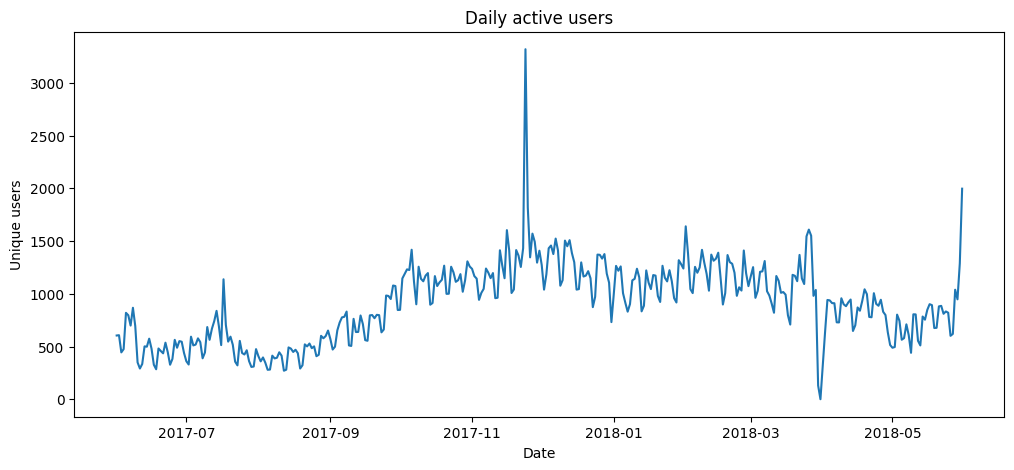

In [21]:
dau_by_day = visits.groupby('session_date')['uid'].nunique()

dau_by_day.plot(figsize=(12, 5))
plt.title('Daily active users')
plt.xlabel('Date')
plt.ylabel('Unique users')
plt.show()

In [22]:
print('Day with most users:', dau_by_day.idxmax(), '|', dau_by_day.max())
print('Day with fewest users:', dau_by_day.idxmin(), '|', dau_by_day.min())
print()

# Days around the lowest point (April 1 has no visits at all) and the last days of the data
print(dau_by_day.loc[pd.Timestamp('2018-03-27').date():pd.Timestamp('2018-04-03').date()])
print()
print(dau_by_day.tail(3))

Day with most users: 2017-11-24 | 3319
Day with fewest users: 2018-03-31 | 1

session_date
2018-03-27    1551
2018-03-28     981
2018-03-29    1037
2018-03-30     131
2018-03-31       1
2018-04-02     641
2018-04-03     942
Name: uid, dtype: int64

session_date
2018-05-29     948
2018-05-30    1289
2018-05-31    1997
Name: uid, dtype: int64


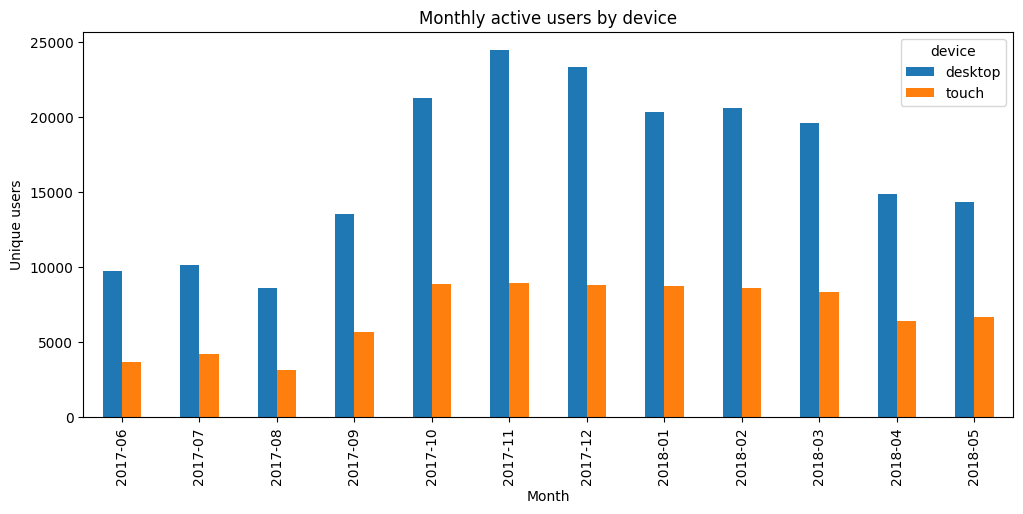

In [23]:
mau_by_device = visits.groupby(['session_month', 'device'], observed=True)['uid'].nunique().unstack()

mau_by_device.plot(kind='bar', figsize=(12, 5))
plt.title('Monthly active users by device')
plt.xlabel('Month')
plt.ylabel('Unique users')
plt.show()

In [24]:
for device in ['desktop', 'touch']:
    device_visits = visits[visits['device'] == device]
    print(f"{device}: DAU {device_visits.groupby('session_date')['uid'].nunique().mean():.0f} | MAU {device_visits.groupby('session_month')['uid'].nunique().mean():.0f}")

desktop: DAU 659 | MAU 16725
touch: DAU 253 | MAU 6826


#### Sessions per day

In [25]:
# One user can open the site more than once a day
sessions_per_day = visits.groupby('session_date').agg(n_sessions=('uid', 'count'), n_users=('uid', 'nunique'))
sessions_per_day['sessions_per_user'] = sessions_per_day['n_sessions'] / sessions_per_day['n_users']

print(f"Sessions per day: {sessions_per_day['n_sessions'].mean():.0f}")
print(f"Sessions per user per day: {sessions_per_day['sessions_per_user'].mean():.2f}")

Sessions per day: 987
Sessions per user per day: 1.08


#### Session length

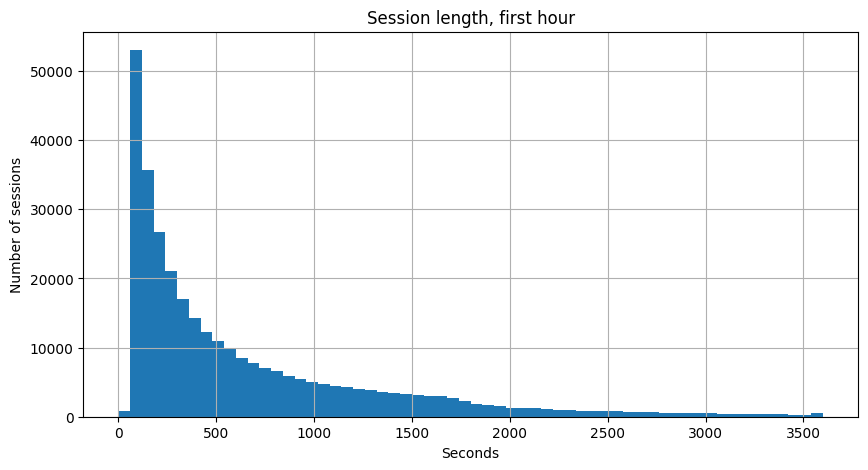

In [26]:
# Zero-second sessions are left out, as decided in Step 1
durations = visits.loc[visits['session_duration_sec'] > 0, 'session_duration_sec']

durations.hist(bins=60, range=(0, 3600), figsize=(10, 5))
plt.title('Session length, first hour')
plt.xlabel('Seconds')
plt.ylabel('Number of sessions')
plt.show()

In [27]:
print(f'Mean: {durations.mean():.0f} seconds')
print(f'Median: {durations.median():.0f} seconds')
print(f'Mode: {durations.mode()[0]:.0f} seconds')

Mean: 714 seconds
Median: 360 seconds
Mode: 60 seconds


In [28]:
visits[visits['session_duration_sec'] > 0].groupby('device', observed=True)['session_duration_sec'].median()

device
desktop    420.0
touch      240.0
Name: session_duration_sec, dtype: float64

#### Retention by monthly cohort

In [29]:
# Cohort = month of the first visit. lifetime = months since the first visit
visits['first_month'] = visits.groupby('uid')['session_month'].transform('min')
visits['lifetime'] = (
    (visits['session_month'].dt.year - visits['first_month'].dt.year) * 12
    + (visits['session_month'].dt.month - visits['first_month'].dt.month)
)

cohorts = visits.groupby(['first_month', 'lifetime'])['uid'].nunique().reset_index()
cohorts['cohort_users'] = cohorts.groupby('first_month')['uid'].transform('first')
cohorts['retention'] = cohorts['uid'] / cohorts['cohort_users']

retention_pivot = cohorts.pivot_table(index='first_month', columns='lifetime', values='retention')

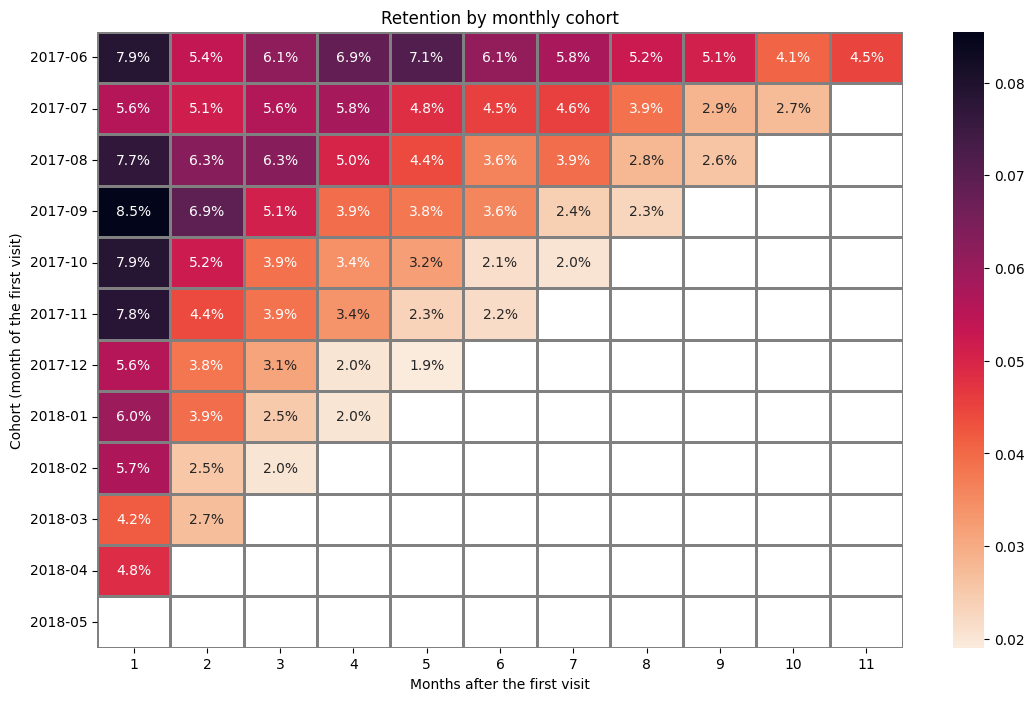

In [30]:
plt.figure(figsize=(13, 8))
# Month 0 is always 100%, so it is left out to make the differences between the other months visible
sns.heatmap(retention_pivot.drop(columns=0), annot=True, fmt='.1%', linewidths=1, linecolor='gray', cmap='rocket_r')
plt.title('Retention by monthly cohort')
plt.xlabel('Months after the first visit')
plt.ylabel('Cohort (month of the first visit)')
plt.show()

In [31]:
print(f"Average retention in the first month after the first visit: {retention_pivot[1].mean():.1%}")

Average retention in the first month after the first visit: 6.5%


#### Step 2 findings

- The site has about 900 users per day, 5,700 per week and 23,000 per month.
- The sticky factor is 16% for the week and 4% for the month, so most people come once a week or less. This is normal for a ticket service: people come when they want to go to an event.
- The audience is seasonal. It grows from September, peaks in November and December and goes down in spring and summer. A possible reason is the events calendar, with big shows and premieres opening their ticket sales. The data does not show the events, so this is a hypothesis to check with the events team.
- The busiest day was November 24, 2017 (Black Friday), with 3,319 users. From March 30 to April 1, 2018 there are almost no visits (131, then 1, then none), and the next day starts at 641. This looks like a gap in the data collection, not a real drop. The last day (May 31) has visits during all 24 hours, so its 1,997 users are a real peak.
- Desktop brings about 2.6 times more users than touch.
- Almost everyone opens the site once a day (1.08 sessions per user).
- The session length is not normal: mean of 714 seconds, median of 360 and mode of 60. The usual session is short, and on touch it is even shorter (median of 4 minutes against 7 on desktop).
- Retention is low: 6.5% come back in the month after the first visit, and then about 4%. The 2018 cohorts come back less. Some older cohorts go up again in autumn: June 2017 goes from 5.4% in August to 7.1% in November. This looks like the busy season bringing people back, not more loyalty.

## Step 3. Sales: when they buy and how much they bring

This step follows the customers: how long they take to buy after the first visit, how many orders they make, how much a purchase is and how much a customer brings over time (LTV). From here on, the cohorts are made by the month of the first order, and the age of a cohort is the number of months since that first order. To compare groups at the same age, some parts use only the cohorts that already had 6 months of data (June to November 2017).

#### Time to the first purchase

In [32]:
# The device and the source of the first visit are kept: this is how the customer arrived,
# and they are used again in Step 4
first_visits = (
    visits.sort_values('start_ts')
    .groupby('uid')
    .first()[['start_ts', 'device', 'source_id']]
    .rename(columns={'start_ts': 'first_visit'})
)
first_orders = orders.groupby('uid')['buy_ts'].min().rename('first_order')

buyers = first_visits.join(first_orders, how='inner')
# Calendar days: a visit at 20:10 and an order at 15:54 on the next day count as 1 day, not 0
buyers['days_to_buy'] = (buyers['first_order'].dt.normalize() - buyers['first_visit'].dt.normalize()).dt.days

buyers.head()

,first_visit,device,source_id,first_order,days_to_buy
uid,,,,,
313578113262317,2017-09-18 22:49:00,desktop,2,2018-01-03 21:51:00,107
1575281904278712,2017-06-03 10:13:00,touch,10,2017-06-03 10:13:00,0
2429014661409475,2017-10-11 17:14:00,desktop,3,2017-10-11 18:33:00,0
2464366381792757,2018-01-27 20:10:00,desktop,5,2018-01-28 15:54:00,1
2551852515556206,2017-11-24 10:14:00,desktop,5,2017-11-24 10:14:00,0


In [33]:
buyers['days_to_buy'].describe()

count    36522.000000
mean        16.896336
std         47.071771
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max        363.000000
Name: days_to_buy, dtype: float64

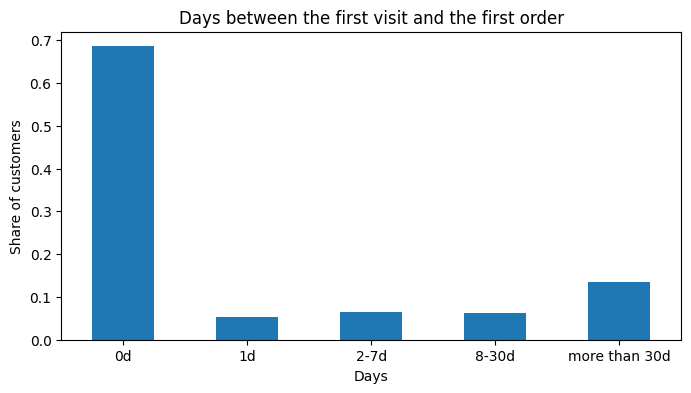

conversion_group
0d               0.685587
1d               0.053803
2-7d             0.063825
8-30d            0.061689
more than 30d    0.135097
Name: proportion, dtype: float64

In [34]:
buyers['conversion_group'] = pd.cut(
    buyers['days_to_buy'],
    bins=[-1, 0, 1, 7, 30, 365],
    labels=['0d', '1d', '2-7d', '8-30d', 'more than 30d']
)

conversion_share = buyers['conversion_group'].value_counts(normalize=True).sort_index()

conversion_share.plot(kind='bar', rot=0, figsize=(8, 4))
plt.title('Days between the first visit and the first order')
plt.xlabel('Days')
plt.ylabel('Share of customers')
plt.show()

conversion_share

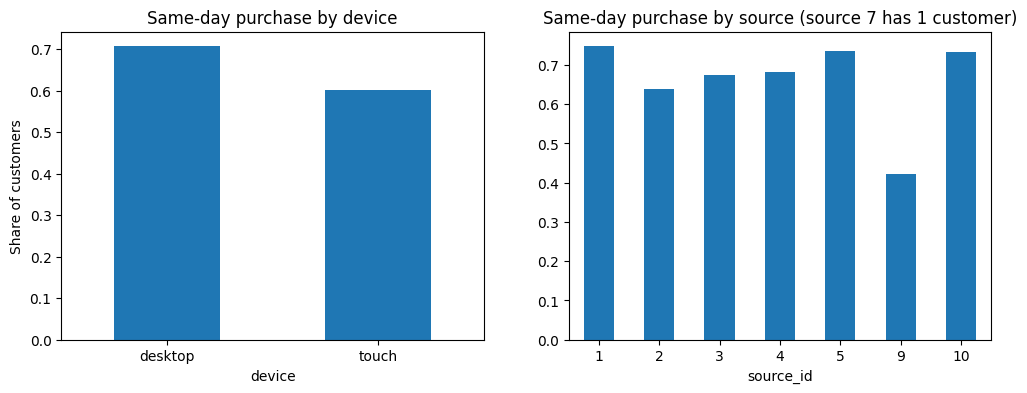

device
desktop    0.707
touch      0.601
Name: days_to_buy, dtype: float64

source_id
1     0.748
2     0.640
3     0.675
4     0.682
5     0.736
7     1.000
9     0.423
10    0.732
Name: days_to_buy, dtype: float64


In [35]:
# Share of customers that bought on the same day as the first visit
same_day_device = buyers.groupby('device', observed=True)['days_to_buy'].apply(lambda days: (days == 0).mean())
same_day_source = buyers.groupby('source_id')['days_to_buy'].apply(lambda days: (days == 0).mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
same_day_device.plot(kind='bar', rot=0, ax=axes[0])
axes[0].set_title('Same-day purchase by device')
axes[0].set_ylabel('Share of customers')
same_day_source.drop(7).plot(kind='bar', rot=0, ax=axes[1])
axes[1].set_title('Same-day purchase by source (source 7 has 1 customer)')
plt.show()

print(same_day_device.round(3))
print()
print(same_day_source.round(3))

#### Orders per customer

In [36]:
orders['order_month'] = orders['buy_ts'].dt.to_period('M')
orders['first_order_month'] = orders.groupby('uid')['order_month'].transform('min')
orders['age'] = (
    (orders['order_month'].dt.year - orders['first_order_month'].dt.year) * 12
    + (orders['order_month'].dt.month - orders['first_order_month'].dt.month)
)

cohorts = (
    orders.groupby(['first_order_month', 'age'])
    .agg(n_orders=('uid', 'count'), revenue=('revenue', 'sum'))
    .reset_index()
)
cohorts['n_buyers'] = cohorts['first_order_month'].map(orders.groupby('first_order_month')['uid'].nunique())
cohorts['orders_per_buyer'] = cohorts['n_orders'] / cohorts['n_buyers']

cohorts.head()

,first_order_month,age,n_orders,revenue,n_buyers,orders_per_buyer
0,2017-06,0,2354,9557.49,2023,1.163618
1,2017-06,1,177,981.82,2023,0.087494
2,2017-06,2,174,885.34,2023,0.086011
3,2017-06,3,226,1931.30,2023,0.111715
4,2017-06,4,292,2068.58,2023,0.144340


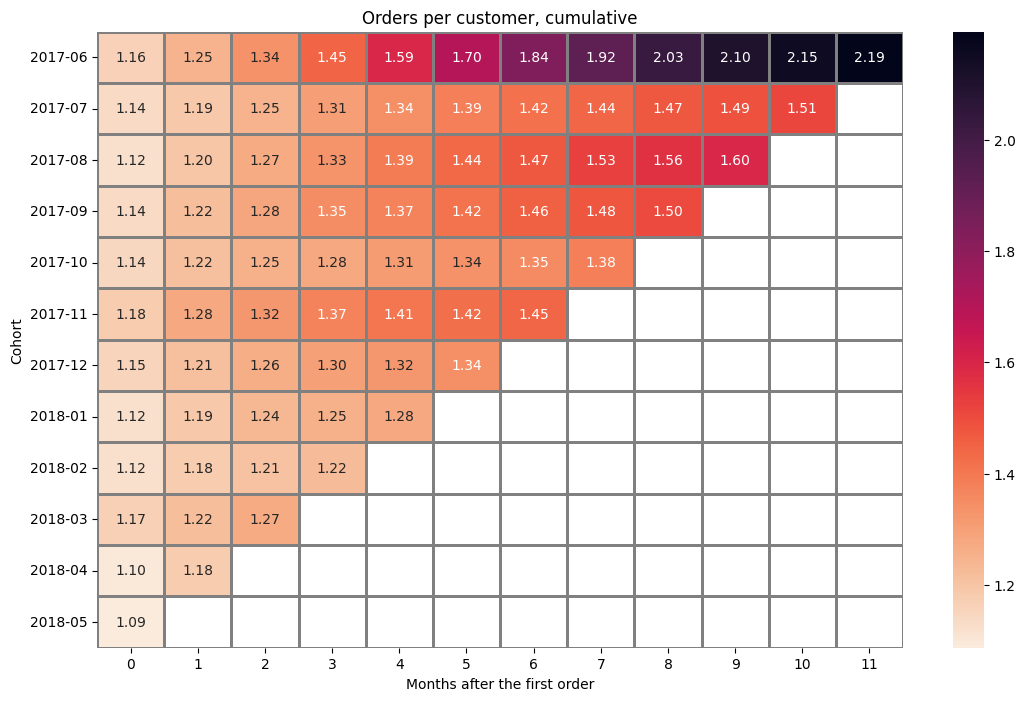

In [37]:
orders_pivot = cohorts.pivot_table(
    index='first_order_month', columns='age', values='orders_per_buyer'
).cumsum(axis=1)

plt.figure(figsize=(13, 8))
sns.heatmap(orders_pivot, annot=True, fmt='.2f', linewidths=1, linecolor='gray', cmap='rocket_r')
plt.title('Orders per customer, cumulative')
plt.xlabel('Months after the first order')
plt.ylabel('Cohort')
plt.show()

In [38]:
print(f"Orders per customer after 6 months: {orders_pivot[5].mean():.2f}")
print(f"Orders per customer in the whole period: {len(orders) / orders['uid'].nunique():.2f}")
print(f"Customers that bought only once: {(orders.groupby('uid').size() == 1).mean():.1%}")

Orders per customer after 6 months: 1.43
Orders per customer in the whole period: 1.38
Customers that bought only once: 82.8%


#### Average purchase

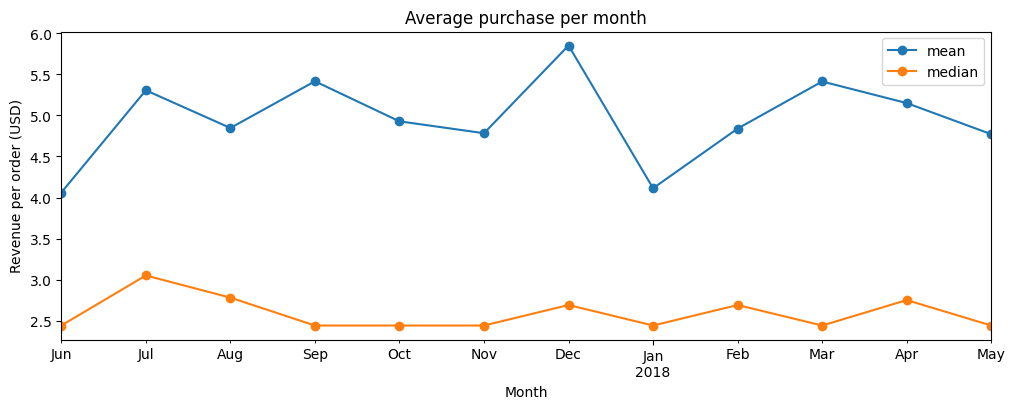

,mean,median
order_month,,
2017-06,4.06,2.44
2017-07,5.31,3.05
2017-08,4.85,2.78
2017-09,5.42,2.44
2017-10,4.93,2.44
2017-11,4.78,2.44
2017-12,5.85,2.69
2018-01,4.11,2.44
2018-02,4.84,2.69


In [39]:
purchase_by_month = orders.groupby('order_month')['revenue'].agg(['mean', 'median'])

purchase_by_month.plot(figsize=(12, 4), marker='o')
plt.title('Average purchase per month')
plt.xlabel('Month')
plt.ylabel('Revenue per order (USD)')
plt.show()

purchase_by_month.round(2)

#### LTV

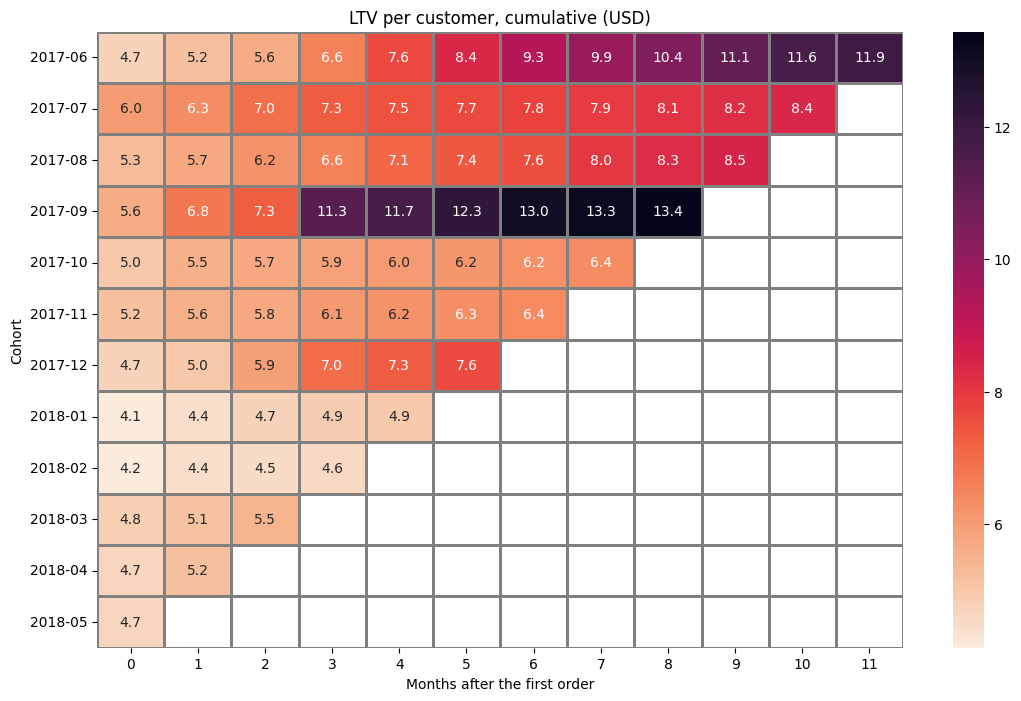

In [40]:
# The revenue is taken as Y.Afisha's own money, so the margin is 100%
cohorts['ltv'] = cohorts['revenue'] / cohorts['n_buyers']

ltv_pivot = cohorts.pivot_table(
    index='first_order_month', columns='age', values='ltv'
).cumsum(axis=1)

plt.figure(figsize=(13, 8))
sns.heatmap(ltv_pivot, annot=True, fmt='.1f', linewidths=1, linecolor='gray', cmap='rocket_r')
plt.title('LTV per customer, cumulative (USD)')
plt.xlabel('Months after the first order')
plt.ylabel('Cohort')
plt.show()

In [41]:
print(f"LTV in the first month: {ltv_pivot[0].mean():.2f}")
print(f"LTV after 6 months: {ltv_pivot[5].mean():.2f}")

LTV in the first month: 4.92
LTV after 6 months: 7.97


#### Purchase and LTV by device

In [42]:
# Device and source of the first visit of each customer (the source is used in Step 4)
orders['device'] = orders['uid'].map(buyers['device'])
orders['source_id'] = orders['uid'].map(buyers['source_id'])

orders.groupby('device', observed=True)['revenue'].agg(['mean', 'median']).round(2)

,mean,median
device,,
desktop,5.16,2.69
touch,4.29,2.44


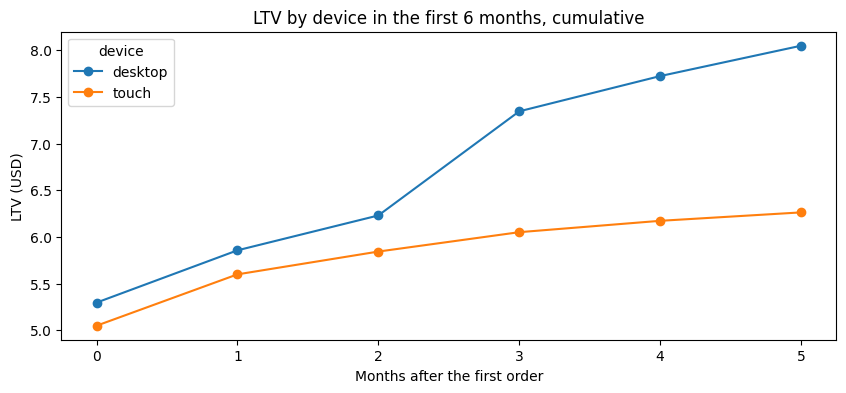

device,desktop,touch
age,,
0,5.30,5.05
1,5.86,5.60
2,6.23,5.84
3,7.35,6.05
4,7.72,6.17
5,8.05,6.26


In [43]:
# Only the cohorts that already had 6 months (June to November 2017), so all of them are compared at the same age
mature_month = pd.Period('2017-11', 'M')
mature_orders = orders[(orders['first_order_month'] <= mature_month) & (orders['age'] <= 5)]
mature_buyers = buyers[buyers['first_order'].dt.to_period('M') <= mature_month]

ltv_by_device = (
    mature_orders.pivot_table(index='age', columns='device', values='revenue', aggfunc='sum', observed=True)
    .cumsum()
    .div(mature_buyers.groupby('device', observed=True).size())
)

ltv_by_device.plot(figsize=(10, 4), marker='o')
plt.title('LTV by device in the first 6 months, cumulative')
plt.xlabel('Months after the first order')
plt.ylabel('LTV (USD)')
plt.show()

ltv_by_device.round(2)

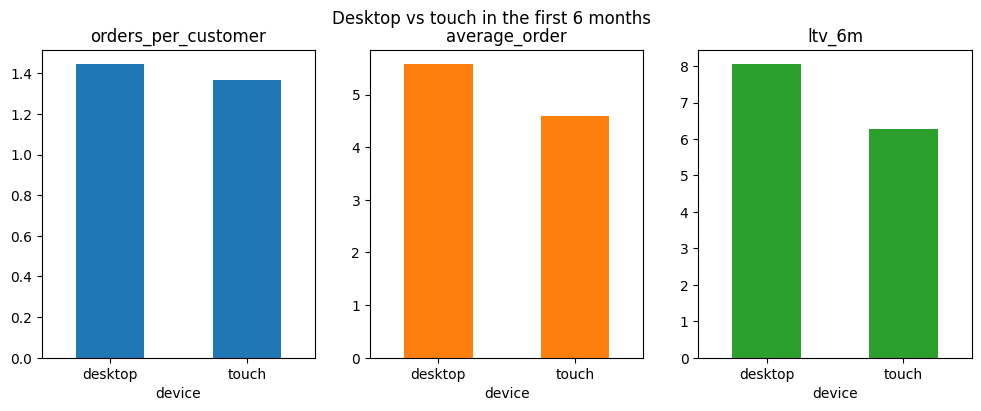

,orders_per_customer,average_order,ltv_6m
device,,,
desktop,1.44,5.58,8.05
touch,1.37,4.59,6.26


In [44]:
# Orders per customer, average order and LTV by device, in the first 6 months of the same cohorts
device_summary = pd.DataFrame({
    'orders_per_customer': mature_orders.groupby('device', observed=True).size() / mature_buyers.groupby('device', observed=True).size(),
    'average_order': mature_orders.groupby('device', observed=True)['revenue'].mean(),
    'ltv_6m': ltv_by_device.iloc[-1],
})

device_summary.plot(kind='bar', subplots=True, layout=(1, 3), figsize=(12, 4), rot=0, legend=False)
plt.suptitle('Desktop vs touch in the first 6 months')
plt.show()

device_summary.round(2)

#### Step 3 findings

- 68.6% of the customers buy on the same calendar day as the first visit, and 5.4% on the next day. The median is 0 days, and the mean of 17 days is pulled up by the 13.5% that take more than a month.
- Desktop converts faster than touch (71% on the first day against 60%). Source 9 is the slowest (42%), and the others stay between 64% and 75%.
- 83% of the customers buy only once. After 6 months, a customer has 1.43 orders on average. June 2017 is the most loyal cohort, with 1.70 orders at the same age.
- A usual purchase is about 2.5 USD (median). The mean stays between 4 and 6 because of a few large orders, with its peak in December.
- Desktop customers bring more: 8.1 USD in 6 months against 6.3 on touch. They make almost the same number of orders (1.44 against 1.37), so the gap comes from bigger orders (5.58 against 4.59 USD on average).
- LTV is 4.9 USD in the first month and 8.0 after 6 months, so most of the value comes with the first purchase. June 2017 reaches 11.9 after a year. September 2017 jumps in the fourth month because of a few big orders, and the 2018 cohorts grow slower.

## Step 4. Marketing: where does the money go?

This step looks at how much was spent on each source, how much one customer costs (CAC) and whether the money came back (ROMI), by cohort and by source. Each customer is linked to the source of the first visit. ROMI is LTV divided by CAC: when it reaches 1, the cost is paid back. The costs don't come by device, so CAC and ROMI are only by source. At the end, the results are checked in two other ways and turned into a budget plan.

#### Costs

Total spent: 329,132

source_id
3     0.429
4     0.186
5     0.157
2     0.130
1     0.063
10    0.018
9     0.017
Name: costs, dtype: float64


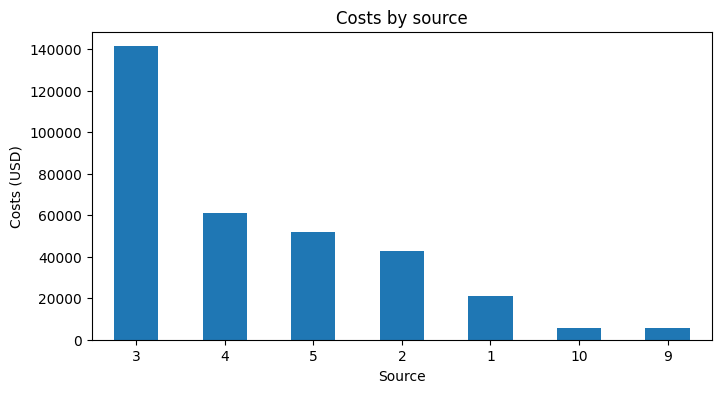

In [45]:
costs_by_source = costs.groupby('source_id')['costs'].sum().sort_values(ascending=False)

print(f"Total spent: {costs['costs'].sum():,.0f}")
print()
print((costs_by_source / costs_by_source.sum()).round(3))

costs_by_source.plot(kind='bar', rot=0, figsize=(8, 4))
plt.title('Costs by source')
plt.xlabel('Source')
plt.ylabel('Costs (USD)')
plt.show()

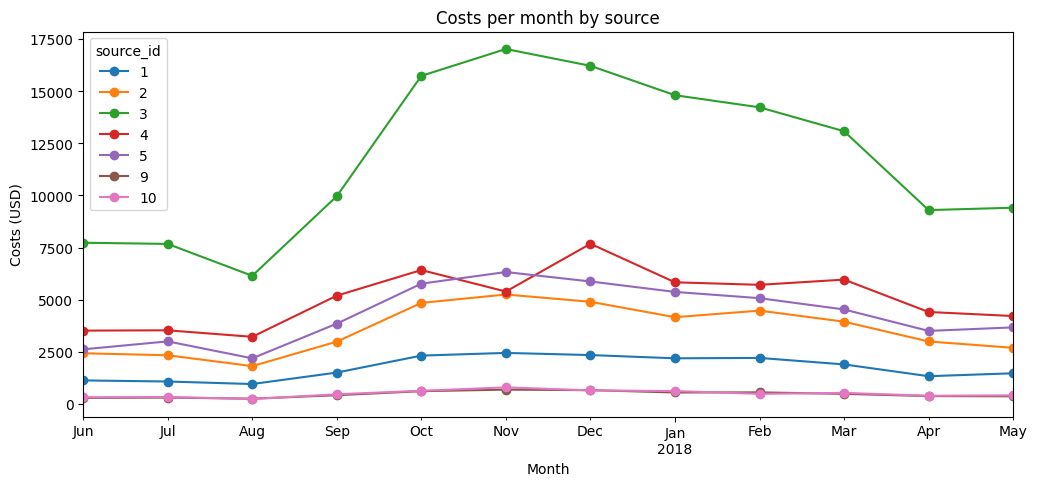

In [46]:
costs['month'] = costs['dt'].dt.to_period('M')

costs.pivot_table(index='month', columns='source_id', values='costs', aggfunc='sum').plot(figsize=(12, 5), marker='o')
plt.title('Costs per month by source')
plt.xlabel('Month')
plt.ylabel('Costs (USD)')
plt.show()

#### CAC by source

In [47]:
# CAC of a source = costs of the source / customers that came from it
cac = pd.DataFrame({
    'costs': costs_by_source,
    'customers': buyers.groupby('source_id').size()
})
cac['cac'] = cac['costs'] / cac['customers']

print(f"CAC of the whole period: {costs['costs'].sum() / len(buyers):.2f}")
cac.sort_values('cac').round(2)

CAC of the whole period: 9.01


,costs,customers,cac
source_id,,,
10,5822.49,1329,4.38
9,5517.49,1088,5.07
4,61073.60,10295,5.93
1,20833.27,2899,7.19
5,51757.10,6931,7.47
2,42806.04,3506,12.21
3,141321.63,10473,13.49
7,NaN,1,NaN


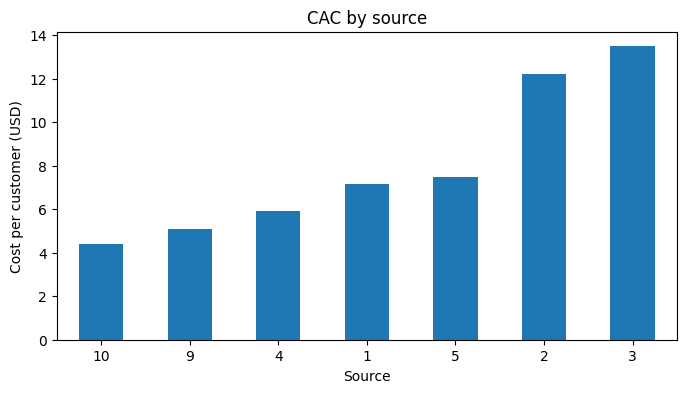

In [48]:
cac['cac'].dropna().sort_values().plot(kind='bar', rot=0, figsize=(8, 4))
plt.title('CAC by source')
plt.xlabel('Source')
plt.ylabel('Cost per customer (USD)')
plt.show()

In [49]:
# Same cohorts on both sides: June to November 2017, the ones with 6 months of data
print(f"CAC: {costs.loc[costs['month'] <= mature_month, 'costs'].sum() / len(mature_buyers):.2f}")
print(f"LTV after 6 months: {mature_orders['revenue'].sum() / len(mature_buyers):.2f}")

CAC: 9.17
LTV after 6 months: 7.71


#### CAC by source over time

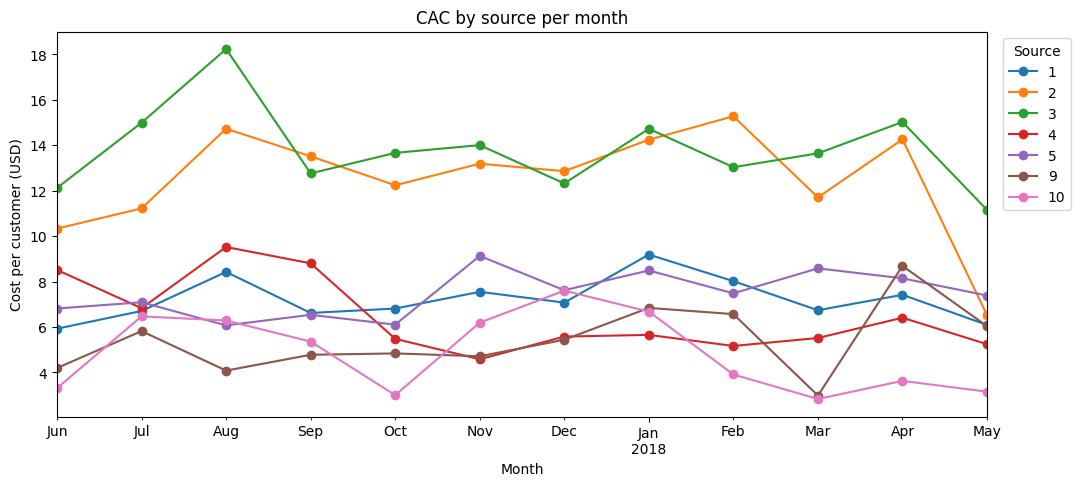

source_id,1,2,3,4,5,9,10
month,,,,,,,
2017-06,5.9,10.3,12.1,8.5,6.8,4.2,3.3
2017-07,6.7,11.2,15.0,6.8,7.1,5.8,6.5
2017-08,8.4,14.7,18.2,9.5,6.1,4.1,6.3
2017-09,6.6,13.5,12.8,8.8,6.5,4.8,5.4
2017-10,6.8,12.2,13.7,5.5,6.1,4.8,3.0
2017-11,7.5,13.2,14.0,4.6,9.1,4.7,6.2
2017-12,7.1,12.9,12.3,5.6,7.6,5.4,7.6
2018-01,9.2,14.2,14.7,5.7,8.5,6.8,6.7
2018-02,8.0,15.3,13.0,5.2,7.5,6.6,3.9


In [50]:
# New customers of each source in each month (month of the first order)
buyers['first_order_month'] = buyers['first_order'].dt.to_period('M')

cac_by_month = (
    costs.groupby(['month', 'source_id'])['costs'].sum()
    / buyers.groupby(['first_order_month', 'source_id']).size().rename_axis(['month', 'source_id'])
).unstack().dropna(axis=1, how='all')

cac_by_month.plot(figsize=(12, 5), marker='o')
plt.title('CAC by source per month')
plt.legend(title='Source', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xlabel('Month')
plt.ylabel('Cost per customer (USD)')
plt.show()

cac_by_month.round(1)

#### ROMI by cohort

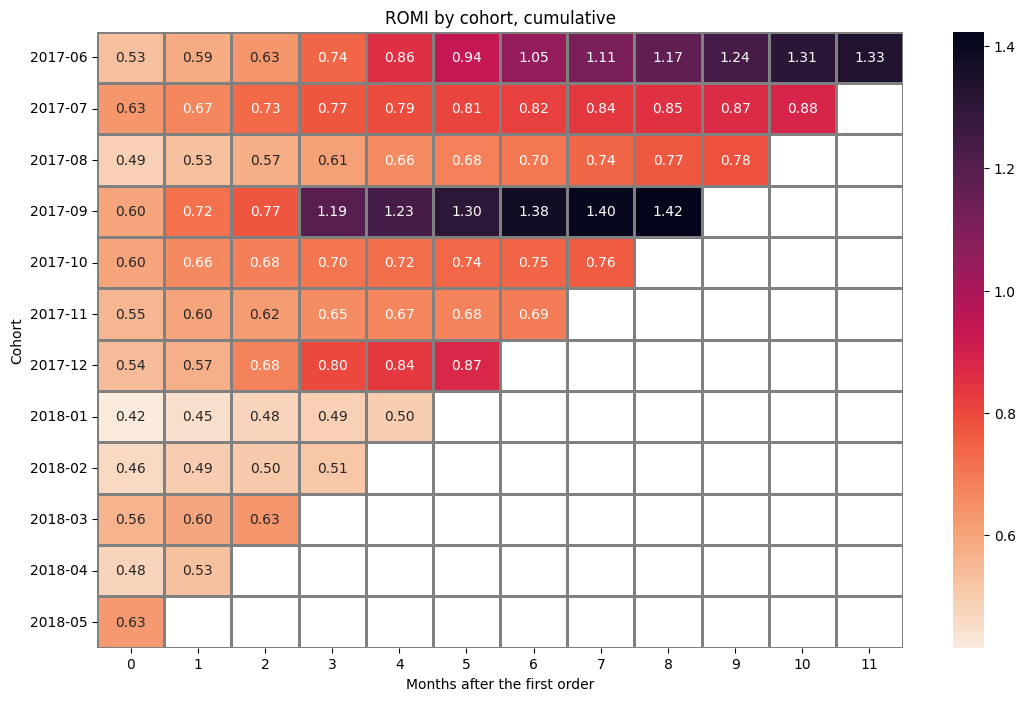

In [51]:
# CAC of a cohort = costs of the month / new customers of the month
cohort_cac = costs.groupby('month')['costs'].sum() / orders.groupby('first_order_month')['uid'].nunique()
cohorts['romi'] = cohorts['ltv'] / cohorts['first_order_month'].map(cohort_cac)

romi_pivot = cohorts.pivot_table(
    index='first_order_month', columns='age', values='romi'
).cumsum(axis=1)

plt.figure(figsize=(13, 8))
sns.heatmap(romi_pivot, annot=True, fmt='.2f', linewidths=1, linecolor='gray', cmap='rocket_r')
plt.title('ROMI by cohort, cumulative')
plt.xlabel('Months after the first order')
plt.ylabel('Cohort')
plt.show()

In [52]:
# The whole period includes the late cohorts, that had only a few months to pay back.
# The 6-month ROMI uses only the cohorts that already had 6 months (June to November 2017):
# their revenue in those 6 months divided by the costs of those months
print(f"Total revenue: {orders['revenue'].sum():,.0f}")
print(f"Total costs: {costs['costs'].sum():,.0f}")
print(f"ROMI of the whole period: {orders['revenue'].sum() / costs['costs'].sum():.2f}")
print(f"ROMI after 6 months: {mature_orders['revenue'].sum() / costs.loc[costs['month'] <= mature_month, 'costs'].sum():.2f}")

Total revenue: 252,054
Total costs: 329,132
ROMI of the whole period: 0.77
ROMI after 6 months: 0.84


#### ROMI by source

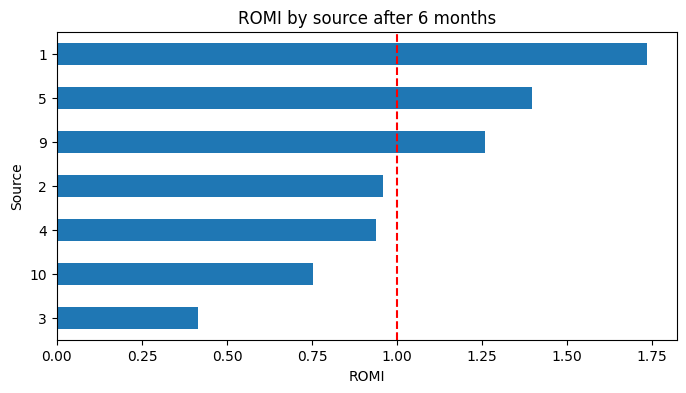

,costs,customers_6m,cac_6m,ltv_6m,romi_6m,romi_total
source_id,,,,,,
3,141321.63,4636,13.86,5.74,0.41,0.39
10,5822.49,606,4.55,3.42,0.75,0.76
4,61073.60,4207,6.48,6.08,0.94,0.93
2,42806.04,1581,12.43,11.92,0.96,1.10
9,5517.49,539,4.72,5.94,1.26,1.04
5,51757.10,3394,7.00,9.78,1.40,1.02
1,20833.27,1354,6.95,12.07,1.74,1.49
7,NaN,1,NaN,1.22,NaN,NaN


In [53]:
buyers['revenue'] = orders.groupby('uid')['revenue'].sum()

# Only the cohorts with 6 months of data (June to November 2017), so every source is compared at the same age
romi_by_source = pd.DataFrame({
    'costs': costs_by_source,
    'customers_6m': mature_buyers.groupby('source_id').size(),
    'cac_6m': costs[costs['month'] <= mature_month].groupby('source_id')['costs'].sum() / mature_buyers.groupby('source_id').size(),
    'ltv_6m': mature_orders.groupby('source_id')['revenue'].sum() / mature_buyers.groupby('source_id').size(),
})
romi_by_source['romi_6m'] = romi_by_source['ltv_6m'] / romi_by_source['cac_6m']

# Whole period, only for comparison
romi_by_source['romi_total'] = buyers.groupby('source_id')['revenue'].sum() / costs_by_source

romi_by_source['romi_6m'].dropna().sort_values().plot(kind='barh', figsize=(8, 4))
plt.axvline(1, color='red', linestyle='--')
plt.title('ROMI by source after 6 months')
plt.xlabel('ROMI')
plt.ylabel('Source')
plt.show()

romi_by_source.sort_values('romi_6m').round(2)

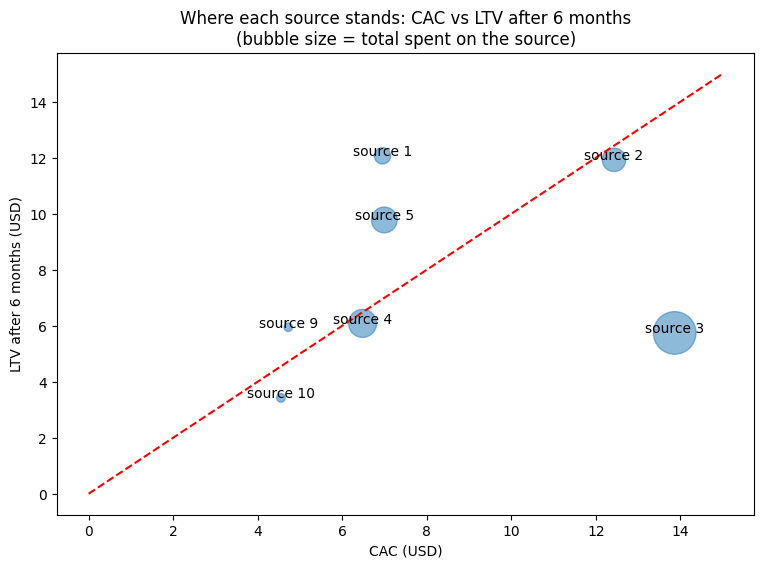

In [54]:
# Each bubble is a source, and its size is the total spent on it.
# Above the red line, the customers bring more than they cost in 6 months
sources = romi_by_source.dropna()

plt.figure(figsize=(9, 6))
plt.scatter(sources['cac_6m'], sources['ltv_6m'], s=sources['costs'] / 150, alpha=0.5)
for source_id, row in sources.iterrows():
    plt.annotate(f'source {source_id}', (row['cac_6m'], row['ltv_6m']), ha='center')
plt.plot([0, 15], [0, 15], 'r--')
plt.title('Where each source stands: CAC vs LTV after 6 months\n(bubble size = total spent on the source)')
plt.xlabel('CAC (USD)')
plt.ylabel('LTV after 6 months (USD)')
plt.show()

#### Do the results hold?

In [55]:
# The same 6-month ROMI, only for the most recent cohorts that already had 6 months (October and November 2017)
recent_month = pd.Period('2017-10', 'M')
recent_orders = mature_orders[mature_orders['first_order_month'] >= recent_month]
recent_costs = costs[(costs['month'] >= recent_month) & (costs['month'] <= mature_month)]

romi_by_source['romi_recent'] = recent_orders.groupby('source_id')['revenue'].sum() / recent_costs.groupby('source_id')['costs'].sum()

# Source of the last visit before the first order, instead of the first visit
last_source = (
    visits.merge(buyers[['first_order']], left_on='uid', right_index=True)
    .query('start_ts <= first_order')
    .sort_values('start_ts')
    .groupby('uid')['source_id'].last()
)
romi_by_source['romi_last_visit'] = buyers.groupby(last_source)['revenue'].sum() / costs_by_source

print(f"Customers whose last source is different from the first: {(last_source != buyers.loc[last_source.index, 'source_id']).mean():.1%}")
romi_by_source[['romi_6m', 'romi_recent', 'romi_last_visit']].dropna().sort_values('romi_6m').round(2)

Customers whose last source is different from the first: 18.7%


,romi_6m,romi_recent,romi_last_visit
source_id,,,
3,0.41,0.38,0.32
10,0.75,0.86,0.77
4,0.94,1.15,0.85
2,0.96,0.85,1.24
9,1.26,1.19,0.82
5,1.40,0.74,1.03
1,1.74,1.25,1.91


#### How much money to move?

In [56]:
# Sources below 1 in every view lose half of their budget.
# Sources above 1 also in the recent cohorts get more, in small steps, because a channel
# that gets much more money usually returns less. Sources 2 and 5 stay as they are
budget_change = {3: -0.5, 10: -0.5, 1: 1.0, 4: 0.25, 9: 0.5}

plan = romi_by_source[['costs', 'cac_6m', 'romi_6m']].dropna()
plan['change'] = (plan['costs'] * pd.Series(budget_change)).fillna(0)
plan['new_costs'] = plan['costs'] + plan['change']
plan['share_now'] = plan['costs'] / plan['costs'].sum()
plan['share_new'] = plan['new_costs'] / plan['new_costs'].sum()

# Customers won or lost, if each source keeps its 6-month CAC
plan['customers_change'] = plan['change'] / plan['cac_6m']

print(f"Taken out: {-plan.loc[plan['change'] < 0, 'change'].sum():,.0f} USD")
print(f"Moved to other sources: {plan.loc[plan['change'] > 0, 'change'].sum():,.0f} USD")
print(f"Kept as a reserve: {-plan['change'].sum():,.0f} USD")
print(f"Customers: {plan['customers_change'].sum():+,.0f}")
print(f"ROMI after 6 months: {(plan['costs'] * plan['romi_6m']).sum() / plan['costs'].sum():.2f} now, "
      f"{(plan['new_costs'] * plan['romi_6m']).sum() / plan['new_costs'].sum():.2f} with the plan")

plan.round(2)

Taken out: 73,572 USD
Moved to other sources: 38,860 USD
Kept as a reserve: 34,712 USD
Customers: +201
ROMI after 6 months: 0.84 now, 1.02 with the plan


,costs,cac_6m,romi_6m,change,new_costs,share_now,share_new,customers_change
source_id,,,,,,,,
1,20833.27,6.95,1.74,20833.27,41666.54,0.06,0.14,2996.66
2,42806.04,12.43,0.96,0.00,42806.04,0.13,0.15,0.00
3,141321.63,13.86,0.41,-70660.82,70660.82,0.43,0.24,-5096.54
4,61073.60,6.48,0.94,15268.40,76342.00,0.19,0.26,2356.02
5,51757.10,7.00,1.40,0.00,51757.10,0.16,0.18,0.00
9,5517.49,4.72,1.26,2758.74,8276.24,0.02,0.03,584.29
10,5822.49,4.55,0.75,-2911.24,2911.24,0.02,0.01,-639.93


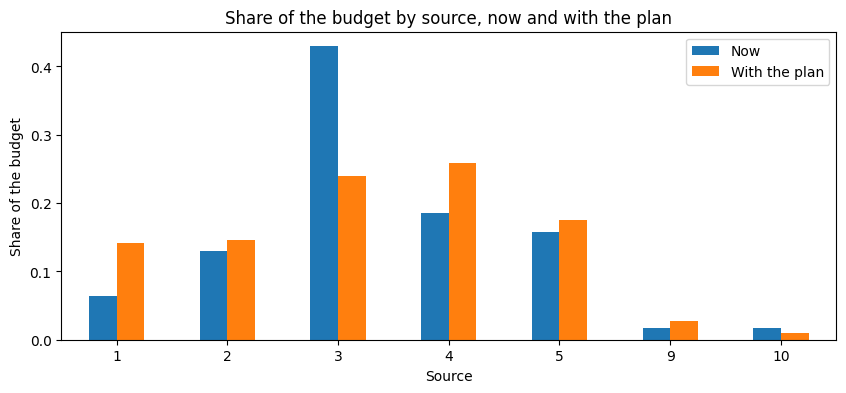

In [57]:
plan[['share_now', 'share_new']].plot(kind='bar', rot=0, figsize=(10, 4))
plt.title('Share of the budget by source, now and with the plan')
plt.xlabel('Source')
plt.ylabel('Share of the budget')
plt.legend(['Now', 'With the plan'])
plt.show()

#### Step 4 findings

- About 329,000 USD were spent in the year. Source 3 takes 43% of the money, and sources 9 and 10 less than 2% each. The spending follows the audience: up from September, down from March.
- Sources 2 and 3 are the most expensive in most months (between 10 and 18 USD per customer). Two points stand out: source 2 drops to 6.5 in May 2018, when its spending fell but it still got 412 new customers, and source 9 jumps to 8.7 in April 2018, a month with only 43 new customers.
- Comparing the same cohorts (June to November 2017), one customer costs 9.2 USD and brings 7.7 in 6 months. The average customer doesn't pay back in half a year.
- The ROMI heatmap shows only June and September 2017 going above 1: June in the seventh month, and September in the fourth, because of a few big orders. The other cohorts stay below 1, and the 2018 cohorts start weaker.
- The marketing did not pay back this year: 329,000 spent and 252,000 brought back (ROMI of 0.77). The cohorts from June to November 2017 reach 0.84 after 6 months. The whole year is lower because the late cohorts had only a few months.
- After 6 months, sources 1 (1.74), 5 (1.40) and 9 (1.26) pay back. Sources 2 (0.96) and 4 (0.94) are close, and source 10 (0.75) and source 3 (0.41) are far from it.
- In the recent cohorts (October and November 2017), sources 1, 4 and 9 stay above 1, and source 4 goes from 0.94 to 1.15 as its CAC fell. Sources 5 and 2 drop below 1.
- With the last visit before the first order as the source (19% of the customers change), source 3 is still the worst (0.32) and source 1 still the best (1.91). Source 9 drops to 0.82, so its result depends on how the customer is counted.
- The plan takes 73,572 USD from sources 3 and 10 (half of each), moves 38,860 to sources 1, 4 and 9 and keeps 34,712 as a reserve. Source 3 goes from 43% to 24% of the budget. The number of customers stays about the same (+201), and the 6-month ROMI goes from 0.84 to about 1.02.
- Source 7 has no costs and only one customer, so it is left out.

## Step 5. Hypothesis test

Do desktop customers spend more than touch customers?

Desktop customers converted faster, so it's worth checking whether they also spend more. Each customer is linked to the device of the first visit, and the revenue of all their orders is added up.

**How the hypotheses were formed**

- Null hypothesis (H0): the average revenue per customer is the same on desktop and touch.
- Alternative hypothesis (H1): the average revenue per customer is different on desktop and touch.

The task doesn't say which one should be higher, so the test is two-sided.

**Which test was used and why**

There are two independent groups, so the test is `st.ttest_ind`. Before the test, Levene's test and the variances of the two groups are checked to choose `equal_var`. Each customer is linked to the device of the first visit. The significance level (alpha) is 0.05.

In [58]:
desktop_revenue = buyers[buyers['device'] == 'desktop']['revenue']
touch_revenue = buyers[buyers['device'] == 'touch']['revenue']

# Mean, variance and standard deviation of each group
print(f'Desktop: {len(desktop_revenue)} customers | mean {desktop_revenue.mean():.2f} | variance {desktop_revenue.var():.2f} | std {desktop_revenue.std():.2f}')
print(f'Touch: {len(touch_revenue)} customers | mean {touch_revenue.mean():.2f} | variance {touch_revenue.var():.2f} | std {touch_revenue.std():.2f}')

Desktop: 29210 customers | mean 7.23 | variance 9529.91 | std 97.62
Touch: 7312 customers | mean 5.57 | variance 721.90 | std 26.87


In [59]:
alpha = 0.05

# Levene's test checks if the two groups have similar variances.
# p-value above alpha: similar variances, equal_var=True
# p-value below alpha: different variances, equal_var=False
levene_results = st.levene(desktop_revenue, touch_revenue)
print('Levene p-value:', levene_results.pvalue)

Levene p-value: 0.17714781095575158


In [60]:
# Levene's p-value is above alpha, but the variances are about 13 times apart and the groups have very different sizes.
# Levene uses the median, so it doesn't see the big orders that make this difference.
# The safer choice here is equal_var=False (Welch's t-test)
results = st.ttest_ind(desktop_revenue, touch_revenue, equal_var=False)

print('The null hypothesis is that the average revenue per customer is the same on desktop and touch')
print('The alternative hypothesis is that the average revenue per customer is different on desktop and touch')
print('p-value:', results.pvalue)

if results.pvalue < alpha:
    print('We reject the null hypothesis')
else:
    print('We cannot reject the null hypothesis')

The null hypothesis is that the average revenue per customer is the same on desktop and touch
The alternative hypothesis is that the average revenue per customer is different on desktop and touch
p-value: 0.010662201279769894
We reject the null hypothesis


In [61]:
# Robustness check: the revenue per customer is very skewed, with orders up to about 2,633.
# Mann-Whitney compares the two groups without using the mean
print('Mann-Whitney p-value:', st.mannwhitneyu(desktop_revenue, touch_revenue, alternative='two-sided').pvalue)

# Welch's t-test again, without the top 1% of customers
top_1 = buyers['revenue'].quantile(0.99)
print('p-value without the top 1%:', st.ttest_ind(desktop_revenue[desktop_revenue <= top_1], touch_revenue[touch_revenue <= top_1], equal_var=False).pvalue)
print()
print(f"Difference of the means: {desktop_revenue.mean() - touch_revenue.mean():.2f} USD with all customers")
print(f"Difference of the means: {desktop_revenue[desktop_revenue <= top_1].mean() - touch_revenue[touch_revenue <= top_1].mean():.2f} USD without the top 1%")

Mann-Whitney p-value: 2.1107641951811416e-07
p-value without the top 1%: 0.0049322863131627025

Difference of the means: 1.66 USD with all customers
Difference of the means: 0.19 USD without the top 1%


#### Step 5 findings

The p-value is about 0.01, so we reject the null hypothesis: desktop customers spend more on average, 7.2 USD against 5.6 in the whole period, a difference of 1.7 USD per customer. Each customer is counted on the device of the first visit.

The result holds in the robustness check: Mann-Whitney and the t-test without the top 1% of customers also reject H0. But without that top 1%, the difference falls to 0.19 USD. So the gap is real, but most of it comes from a small group of desktop customers with very big orders.

## Conclusion

The marketing spent more than it brought back this year (ROMI of 0.77). Most of the problem is where the money goes: a few sources pay back and one big source doesn't.

**Why cut source 3 if it brings the most customers?**

Bringing many customers is not the same as bringing money. Source 3 brings the most customers (about 10,500 in the year), but they are the most expensive (13.9 USD each) and spend little (5.7 in 6 months). For each 1 USD spent there, only 0.41 comes back, and it's the worst source in every way it was measured.

**How much to move, and where**

The rule: sources below 1 in every view lose half of their budget, and sources above 1 also in the recent cohorts get more, in small steps.

| Source | Now (USD) | Change | With the plan (USD) | Why |
|---|---|---|---|---|
| 3 | 141,322 | -50% | 70,661 | ROMI of 0.41, the worst in every view |
| 10 | 5,822 | -50% | 2,911 | Cheap customers (4.6) who spend the least (3.4 in 6 months) |
| 1 | 20,833 | +100% | 41,667 | The best ROMI in every view (1.74 after 6 months) |
| 4 | 61,074 | +25% | 76,342 | Its CAC fell during the year, and the recent cohorts pay back (1.15) |
| 9 | 5,517 | +50% | 8,276 | Pays back (1.26), but it's small and depends on how customers are counted |
| 2 and 5 | 94,563 | 0% | 94,563 | Above 1 in some views and below in others |

- This takes 73,572 USD out (22% of the budget), moves 38,860 to sources 1, 4 and 9 and keeps 34,712 as a reserve.
- Source 3 goes from 43% to 24% of the budget, and the number of customers stays about the same (+201).
- If each source keeps its current 6-month ROMI, the total goes from 0.84 to about 1.02. This is the best case, because sources usually return less when they get more money.
- The change can be made in four quarterly steps, checking the ROMI of each source after each step. The reserve goes to the sources that stay above 1.

**Sources 4 and 10 are both below 1. Why keep one and cut the other?**

Source 4 is getting better: its CAC fell from 8.5 to about 5 USD, and its recent cohorts already pay back (1.15). It also brings about 10,000 customers a year. Source 10 is small and its customers spend the least, so even with a low CAC it stays below 1.

**What to keep in mind**

- **Desktop is not part of the plan.** Desktop customers convert faster and spend more, but the costs don't come by device, so there is no ROMI by device. It's worth testing once the team can split costs by device.
- The sources are the ad channels from `source_id`. The data does not give their real names, so the team needs to match each number to its channel.
- Each customer is credited to the source of the first visit. With the last visit, the ranking of sources 3 and 1 doesn't change, but source 9 drops below 1.
- The revenue was taken as Y.Afisha's own money (margin of 100%). If the real margin is lower, all the ROMI values go down, so they are safer to read as a ranking between sources.
- The plan uses the 2017 cohorts, the only ones with 6 months of data. The 2018 cohorts started weaker, which is one more reason to move the money in steps.
- The data covers only one year, from June 2017 to May 2018.